# **Exercise 2 · Boston house prices**

### **plot Setup & Imports**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'FreeSerif', 'DejaVu Serif'],
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
})
SKY, SKY_EDGE = '#9AD0EC', '#5BA8D6'
YELLOW, YELLOW_EDGE = '#F8DC75', '#D9B93A'
GRAY = '#8A94A6'

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

SEED = 42

### **Load the data**

In [2]:
boston = pd.read_csv('boston_house_prices.csv', skiprows=1)
X = boston.drop(columns='MEDV')
y = boston['MEDV']
print('Shape:', boston.shape)
print('Missing values:', int(boston.isna().sum().sum()))
print('MEDV capped at 50.0:', int((y == 50).sum()), 'towns')
boston.describe().loc[['min', 'mean', 'max']].round(2)

Shape: (506, 14)
Missing values: 0
MEDV capped at 50.0: 16 towns


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
min,0.01,0.00,0.46,0.00,0.38,3.56,2.90,1.13,1.00,187.00,12.60,0.32,1.73,5.00
mean,3.61,11.36,11.14,0.07,0.55,6.28,68.57,3.80,9.55,408.24,18.46,356.67,12.65,22.53
max,88.98,100.00,27.74,1.00,0.87,8.78,100.00,12.13,24.00,711.00,22.00,396.90,37.97,50.00


### **Q2 (a) · Split the data**

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print('Train:', X_train.shape, '| test:', X_test.shape)

Train: (404, 13) | test: (102, 13)


### **Q2 (b) · Random forest with 100 trees**

In [4]:
rf = RandomForestRegressor(n_estimators=100, random_state=SEED).fit(X_train, y_train)
pred_train = rf.predict(X_train)
pred_test = rf.predict(X_test)

### **Q2 (c) · Metrics**

In [5]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'MAE': mean_absolute_error(y_true, y_pred),
            'MAPE (%)': 100 * mean_absolute_percentage_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}


metrics = pd.DataFrame({'train': regression_metrics(y_train, pred_train),
                        'test': regression_metrics(y_test, pred_test)}).round(3)
metrics

,train,test
MSE,1.966,7.880
RMSE,1.402,2.807
MAE,0.899,2.037
MAPE (%),4.510,11.087
R2,0.977,0.893


### **Q2 (d) · Ground truth vs predictions**

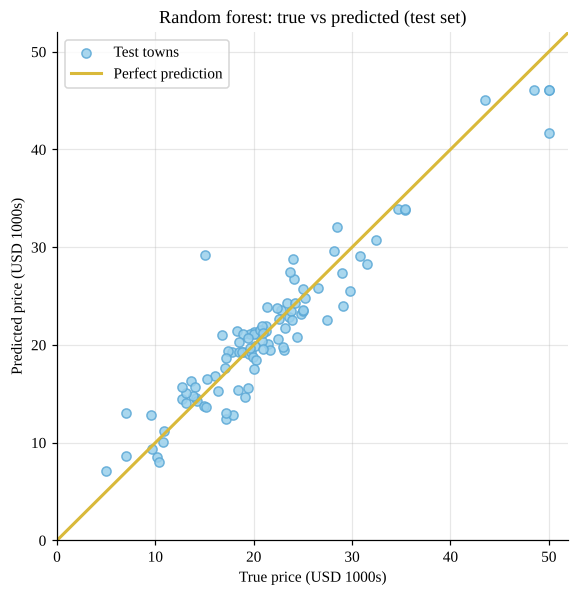

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, pred_test, color=SKY, edgecolor=SKY_EDGE, alpha=0.85, label='Test towns')
lims = [0, 52]
ax.plot(lims, lims, color=YELLOW_EDGE, linewidth=2, label='Perfect prediction')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('True price (USD 1000s)')
ax.set_ylabel('Predicted price (USD 1000s)')
ax.set_title('Random forest: true vs predicted (test set)')
ax.legend()
plt.show()

### **Q2 (e) · 50, 100 and 200 trees**

In [7]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for n in [50, 100, 200]:
    model = RandomForestRegressor(n_estimators=n, random_state=SEED).fit(X_train, y_train)
    p = model.predict(X_test)
    cv_rmse = -cross_val_score(RandomForestRegressor(n_estimators=n, random_state=SEED),
                               X_train, y_train, cv=cv, scoring='neg_root_mean_squared_error')
    rows.append({'trees': n, 'test RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'test R2': r2_score(y_test, p), 'CV RMSE (train rows)': cv_rmse.mean(),
                 'CV RMSE std': cv_rmse.std()})
trees = pd.DataFrame(rows).round(3)
trees

,trees,test RMSE,test R2,CV RMSE (train rows),CV RMSE std
0,50,2.748,0.897,3.763,0.598
1,100,2.807,0.893,3.748,0.596
2,200,2.932,0.883,3.735,0.588


### **Q2 (f) · RMSE in dollars**

In [8]:
trees['test RMSE (USD)'] = (trees['test RMSE'] * 1000).round(0)
trees['CV RMSE (USD)'] = (trees['CV RMSE (train rows)'] * 1000).round(0)
trees['CV std (USD)'] = (trees['CV RMSE std'] * 1000).round(0)
trees[['trees', 'test RMSE (USD)', 'CV RMSE (USD)', 'CV std (USD)']]

,trees,test RMSE (USD),CV RMSE (USD),CV std (USD)
0,50,2748.0,3763.0,598.0
1,100,2807.0,3748.0,596.0
2,200,2932.0,3735.0,588.0


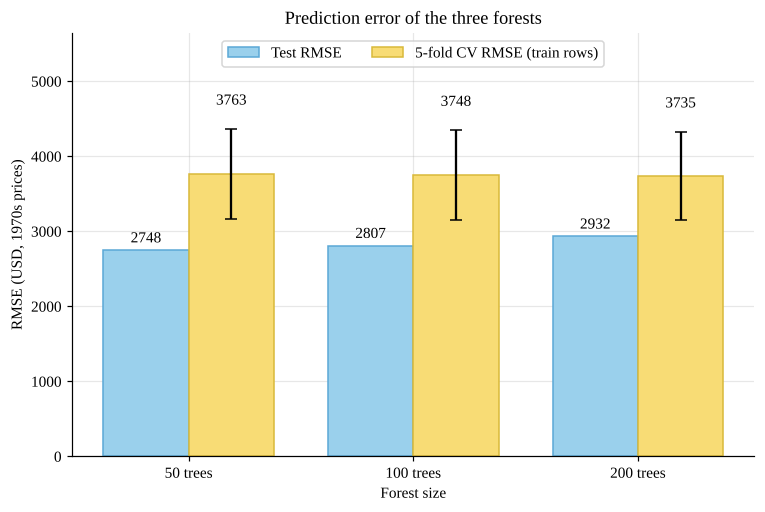

In [9]:
x = np.arange(len(trees))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w / 2, trees['test RMSE (USD)'], w, color=SKY, edgecolor=SKY_EDGE, label='Test RMSE')
b2 = ax.bar(x + w / 2, trees['CV RMSE (USD)'], w, yerr=trees['CV std (USD)'], capsize=4,
            color=YELLOW, edgecolor=YELLOW_EDGE, label='5-fold CV RMSE (train rows)')
ax.bar_label(b1, fmt='%.0f', padding=3)
ax.bar_label(b2, fmt='%.0f', padding=14)
ax.set_xticks(x, [f'{n} trees' for n in trees['trees']])
ax.set_ylim(0, trees['CV RMSE (USD)'].max() * 1.5)
ax.set_xlabel('Forest size')
ax.set_ylabel('RMSE (USD, 1970s prices)')
ax.set_title('Prediction error of the three forests')
ax.legend(loc='upper center', ncol=2)
plt.show()

### **Extra · Sensitivity without the column `B`**

In [10]:
X_tr_nb, X_te_nb = X_train.drop(columns='B'), X_test.drop(columns='B')
rf_nb = RandomForestRegressor(n_estimators=100, random_state=SEED).fit(X_tr_nb, y_train)
p_nb = rf_nb.predict(X_te_nb)
pd.DataFrame({'with B': regression_metrics(y_test, pred_test),
              'without B': regression_metrics(y_test, p_nb)}).round(3)

,with B,without B
MSE,7.880,8.066
RMSE,2.807,2.840
MAE,2.037,2.041
MAPE (%),11.087,11.066
R2,0.893,0.890
